# AP3751 Homework 1 2025-2026 (DEADLINE MAY 7)

**This is the first of three compulsory homeworks. Together the homeworks constitute 40% of your grade.**

The deadline for THIS homework is May 7, 5pm CEST.

After each deadline, we will grade your latest pre-deadline commit.

**We will only accept submissions via GitLab**

To hand-in, do the following: 
1. Log in to gitlab.tudeft.nl with your uni account.
2. Request access to this group https://gitlab.tudelft.nl/ap3751-homework-2026.
3. Click 'Create new project' name it 'ap3751-2026-YOURFAMILYNAME'.
4. Download this file and fill in the ### YOUR SOLUTION ### cells (**read ALL the instructions first ;)**).
5. Remember to push regularly to avoid last minute GitLab problems with your submission.

**General guidelines:**

* Please make your code readable and comment it well (no lenghy descriptions necessary, but individual steps should be well separated and purpose of each step should be made clear; no verbose AI generated comments please).
* If you're plotting something, make sure the plot has axis labels, legends, and is easy to read (pay attention to clear visuals and color choices), if physical units are relevant you need to include them to earn full points.
* If you are using genAI to work on specific subproblem, we encourage you disclose in the comments how you used it.

*Please fill in your details:*

Name: Lilly-Anne Kalderén

Student number:5063841

Declation: Hereby I declare that I produced the code below by myself. I understand that I am responsible for the outcome and I am able to explain in detail the code below.

Links I used to help with Exercise 1:
-https://medium.com/@alokanand002/forward-back-propagation-explained-aff6fb0e93e5 


-https://towardsdatascience.com/implementing-simple-neural-network-backpropagation-from-scratch-baba8a92d232/ 


-https://www.geeksforgeeks.org/deep-learning/the-role-of-weights-and-bias-in-neural-networks/ 



AI was used for debugging and figuring out issues. Theses issues include types, dimensional errors and adjusting the transpose or dot product order 



Exercise 2:
I used the following links:

- https://www.geeksforgeeks.org/data-analysis/principal-component-analysis-pca/

-https://medium.com/technological-singularity/build-a-principal-component-analysis-pca-algorithm-from-scratch-7515595bf08b

I used AI to check some dimensional things and to make the plots 'pretty' here

The AI I used was ChatGPT and Gemini


# Exercise 1: Backpropagation

In the lecture, we learned how to calculate forward and backward pass through this neural network:

<img src="HW-NN-2025.png" alt="NN" width="500"/>


In this exercise you will write you own full training routine for this neural network. In this exercise (and only in this exercise!) you are not allowed to use PyTorch.

**Your task:**

We ask you to train this network to approximate the [XOR](https://en.wikipedia.org/wiki/XOR_gate) function defined by the following table: 

<img src="XOR.png" alt="NN" width="500"/>

Meaning, your input will be pairs (A,B) and your desired outputs (what you want y to be) are A XOR B.


**Specific implementation instructions:**

1. Please include activation functions (choose your favorite).
2. Please include biases in the hidden and output layer.
3. Please initialize your weights and biases using random numbers. (*Hint 1: you might want to fix the random seed to ease testing and debugging.*, *Hint 2: pick the random numbers from the reasonably chosen distribution*)
4. Implement a training loop that will calculate forward and backward pass through the network and updates the weights (very simple update is fine). (*Hint: You will likely need a few thousand iterations*)
5. Plot your loss function as a function of the learning steps (don't forget axes labels; no ugly plots please!).
6. Print your final weights.
7. Assess how well the learned weights actually aproximate the target function (use a markdown cell for qualitative comments).
8. Add more (decide by yourself what 'more' means) neurons in the middle layer and comment on how it influnces the convergence of your model.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


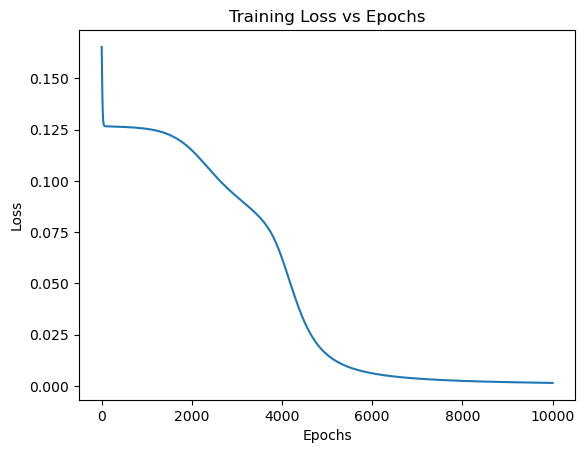

Inputting [1,0] gives: 0.9470714545866143
Inputting [0,1] gives: 0.9473359754180988
Inputting [1,1] gives: 0.05691099938584572
Inputting [0,0] gives: 0.05759504444994132


In [ ]:

#The labels (q,w,a,etc are from the neural network diagrams in the sldies)

#Initialize and define our data
input_data = np.array([[0,0],[0,1],[1,0],[1,1]])
output_data = np.array([0,1,1,0])

#Step 2: Forward pass, to do this we need our weights and biases
class neuralnetwork:
    def __init__(self, input_size, hidden_size, output_size, epsilon):
        
        np.random.seed(26)
        #Define weights and biases where w is to the hidden layer and a the output
        self.w = np.random.rand(input_size * hidden_size) #weights in order w11,w12,w21,w22
        self.w = np.reshape(self.w, (hidden_size, input_size)) #AI used because I had a typo here I had a 1D array the size of the hidden_size * input_size
        self.w_bias = np.random.rand(hidden_size,1)

        #From hidden layer to output
        self.a = np.random.rand(hidden_size * output_size)
        self.a = np.reshape(self.a, (output_size, hidden_size)) #Same as above
        self.a_bias = np.random.rand(output_size,1)

        self.learn_rate = epsilon


    #Define the activation function
    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def sigmoid_derivative(self, x):
        return x * (1 - x)

    
    #Implement the forward pass

    def forward_pass_sigmoid(self,inputs):
        self.inputs = inputs.reshape(-1, 1) #From AI how to reshape as coulmn vector to match slide format
        self.z_in = np.dot(self.w,self.inputs) + self.w_bias #This term is the hidden layer before the activation function
        self.q = self.sigmoid(self.z_in) #Apply the activation function
        self.z_out = np.dot(self.a,self.q) + self.a_bias #This term is from the hidden layer to the output
        self.y = self.sigmoid(self.z_out) #The term is the output multiplied by the activation function
        return self.y[0,0] # I want this to be a scalar instead of a 1,1 array because it was giving errors

#Step 3 calculate the loss function
    def loss_funct(self,y,output):
        return 0.5*(self.y - output)**2
    
    def loss_funct_deri(self,y,output):
        return self.y - output
#step 4 calculate the backpropgoation
    def backprop(self,inputs,outputs):
        #The gradients are found throguh the chain rule looking at the neural network
        # For the a1 and a2
        self.a_updates = np.dot(self.sigmoid_derivative(self.y) * self.loss_funct_deri(self.y,outputs),self.q.T)
        
    
        # AI used in the following section to adjust the weights. I had some of the dot product orders incorrect and transposes 
        #For the w11,w12,w21,w22 weights start with

        self.dy_dz_out = self.sigmoid_derivative(self.y)
        self.d_z_out_dq = self.a.T
        self.dq_d_z_in = self.sigmoid_derivative(self.q)
        self.d_z_in_d_w = inputs.T


       #  dL/dy * dy/dzout scalar
        self.grad_step1 = self.loss_funct_deri(self.y, outputs) * self.sigmoid_derivative(self.y)

       # dot product with dz_out_dq transpose  
        self.grad_step2 = np.dot(self.d_z_out_dq,self.grad_step1)

       # Above multiply with the signmoid derivative 
        
        self.grad_step3 =  self.grad_step2 * self.sigmoid_derivative(self.q)
     
        #multiply by the inputs to get matrix (what we expect for weights)
        self.grad_step4 = np.dot(self.grad_step3, self.inputs.T)

        self.w_updates = self.grad_step4 
        

        self.w -= self.learn_rate * self.w_updates
        self.a -= self.learn_rate * self.a_updates


        #Adjust the biases
        #For the output layer:
        #The first two steps are the same and the dzout/db2 term = 1 
        self.bias_a_updates = self.sigmoid_derivative(self.y) * self.loss_funct_deri(self.y,outputs)
        self.a_bias -= self.learn_rate * self.bias_a_updates

        #For the hidden layer
        self.w_bias -= self.learn_rate * self.grad_step3


        return self.w, self.a, self.a_bias, self.grad_step3
    
        

input_size = 2
hidden_size = 2
output_size = 1
epsilon = 0.1
epochs = 10000

#Make a function to train the network
def train_network(input_size, hidden_size, output_size, epsilon,epochs,input_data,output_data):
    loss = []
    nn = neuralnetwork(input_size, hidden_size, output_size, epsilon)
    for i in range(epochs+1):
        loss_epoch = 0 #This is so that we take the average losses for each of the 4 inputs 
        for i in range(4):
            y_predict = nn.forward_pass_sigmoid(input_data[i]) #call this to determine the losses 
            loss_epoch += nn.loss_funct(y_predict,output_data[i])[0, 0] #calculate the loss
            nn.backprop(input_data[i],output_data[i]) #Call this to update the weights
        loss.append(loss_epoch/4)
    return loss,nn

loss, nn= train_network(input_size, hidden_size, output_size, epsilon, epochs, input_data, output_data)

#AI to make the plot pretty

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss vs Epochs")
plt.plot(np.arange(epochs + 1),loss)
plt.show()

#Show that it works!
print(f'Inputting [1,0] gives: {nn.forward_pass_sigmoid(np.array([1,0]))}') 
print(f'Inputting [0,1] gives: {nn.forward_pass_sigmoid(np.array([0,1]))}') 
print(f'Inputting [1,1] gives: {nn.forward_pass_sigmoid(np.array([1,1]))}') 
print(f'Inputting [0,0] gives: {nn.forward_pass_sigmoid(np.array([0,0]))}') 


The loss for 2 neurons in the hidden layer is:0.0015180372893958
The loss for 4 neurons in the hidden layer is:0.0013483348607947246
The loss for 6 neurons in the hidden layer is:0.001358570433113966
The loss for 8 neurons in the hidden layer is:0.0018233608586178042
The loss for 10 neurons in the hidden layer is:0.0009186436818159147
The loss for 12 neurons in the hidden layer is:0.0011395453669502038


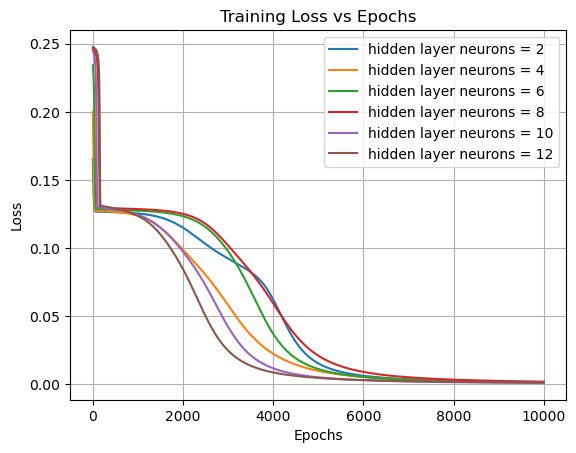

In [ ]:
# increase the network

hidden_layers = np.array([2,4,6,8,10,12])

for i in hidden_layers:
    loss, nn= train_network(input_size, i, output_size, epsilon, epochs, input_data, output_data)
    plt.plot(np.arange(epochs + 1),loss,label = f'hidden layer neurons = {i}')
    print(f'The loss for {i} neurons in the hidden layer is:{loss[-1]}')

#AI to make the plot pretty
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss vs Epochs")
plt.legend()
plt.grid(True)
plt.show() 


The results get bettern when we go from 2 to 4 neurons, and stay consistent for 6. The loss gets worse for 8 slightly, but improves significantly for 10 neurons. For 12 neurons we still have a better result than 8, but worse than 10 neurons. This suggests that overal it converges quicker for more neurons, but it is not a linear decrease.

Looking at the dip around 2000 we see that the networsk with 10 and 12 drop the quickest, but it is interesting that the network with 8 drops slower. Future improvements would be to also look at different learning rates and adjust the number of hidden layers

# Exercise 2: Ising dateset: PCA

In this exercise you will reproduce the Principal Component Analysis we showed you in the first lecture. 

Tasks:

1. Import the classical Ising model dataset that you also used in Exercise Class Week 2 ([see the notebook here](https://colab.research.google.com/drive/10IHFnpCRWLXHZSbuIpqtqGDNffGY2zx9?usp=sharing)).
2. Write your own PCA code (please do NOT use existing implementation from scikit-learn or similar) and apply it on the dataset. Outside of using ready-to-use implementation, you may implement the PCA however you want.
(*Hint: To organize your dataset into a single matrix, you want to flatten every 2D configuration in a single column vector.*)
3. Reproduce the plot below (the style does not need to be 1:1, but please no ugly plots :) ).

<img src="pca.png" alt="pca-plot" width="300"/>

Useful references:
* https://en.wikipedia.org/wiki/Principal_component_analysis
* https://arxiv.org/abs/1606.00318 

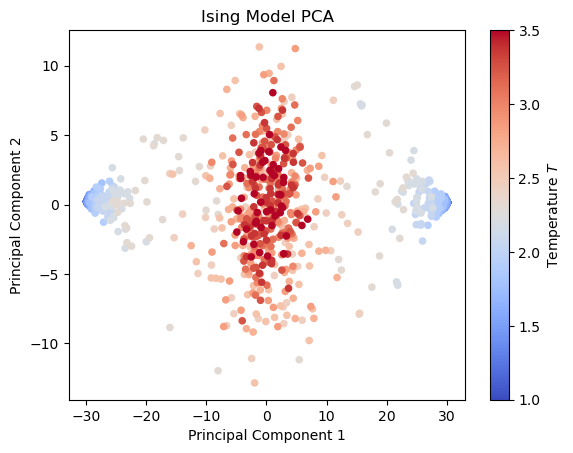

In [ ]:
import numpy as np
from scipy import linalg as la
import matplotlib.pyplot as plt

#30x30 square lattices so we have 900 sins in 1 lattice and 1000 sample

#upload data, use AI some of the format was off 
directory = "/Users/lilly-anne/Desktop/ap3751-2026-kalderen"
config_ising = np.load(f"{directory}/ising_training_configs_30x30.npy", allow_pickle=True)
label_ising = np.load(f"{directory}/ising_training_labels_30x30.npy", allow_pickle=True)

#Reshape to get the 1000 samples each with 900 pixels double checked with AI that this was done correctly 
config_reshape = config_ising.reshape(config_ising.shape[0], -1) 

#Start by standardizing the data 
mean_config = np.mean(config_reshape,axis=0)
config_standard_dev= np.std(config_reshape,axis=0)
config_standardized = (config_reshape - mean_config)/config_standard_dev

#Calculate the covariance matrix and eigenvalues
cov_matrix = np.cov(config_standardized,rowvar=False,dtype=None) 
eigen_vals, eigen_vecs = la.eigh(cov_matrix)
index  = np.argsort(eigen_vals)[::-1] #reindex so that we get the eigen values and vectors from high to low
eiegen_vals = eigen_vals[index]
eigen_vecs = eigen_vecs[:, index]

proj_matrix = eigen_vecs[:,:2] #The two eigen vectors corresponding to the highest eigenvalues used as PCAs. Checked and corrected with AI that the projection matrix was correct

ising_proj = np.dot(config_standardized,proj_matrix) #Apply the projection


#AI used to make the plots pretty
plt.scatter(ising_proj[:, 0], ising_proj[:, 1], c=label_ising, cmap='coolwarm', s=20)
plt.colorbar(label='Temperature $T$')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Ising Model PCA')
plt.show()